# Variational Ansatz — Problem-Inspired Ansatz (CUDA-Q)
### Chapter: Variational Ansatz Design — Problem-Inspired vs. Hardware-Efficient

**Primitive:** QAOA-style *problem-inspired* ansatz for Max-Cut on a triangle graph (K3),
matched exactly to the companion Qiskit notebook.

## SETUP (identical in the matched Qiskit notebook)
- **N_QUBITS** = 3
- **Graph / edges** = triangle graph K3: `[(0,1), (1,2), (0,2)]` (Max-Cut problem)
- **Gate sequence**:
  1. `H` on every qubit (creates the |+⟩^⊗3 initial state)
  2. **Cost unitary** $U_C(\gamma)=\exp\!\big(-i\gamma\sum_{(i,j)\in E} Z_iZ_j\big)$, one
     `CX(i,j) → RZ(2γ) on j → CX(i,j)` block per graph edge, in the order
     `(0,1), (1,2), (0,2)`
  3. **Mixer unitary** $U_M(\beta)=\exp\!\big(-i\beta\sum_k X_k\big)$, one `RX(2β)` per qubit
- **Fixed parameters (this demo)**: `GAMMA = π/4`, `BETA = π/8`
- **QUBIT ORDERING CONTRACT**: this project's shared convention is qubit 0 = rightmost
  bit. **CUDA-Q's native convention is the opposite**: `cudaq.get_state()` and
  `cudaq.sample()` index qubit 0 as the **most-significant (leftmost)** bit. This
  notebook explicitly reverses every bitstring/index before comparing to Qiskit — see
  the dedicated "bit-order remapping" cell below.
- **SHOTS** = 10000, **SEED** = 42
- **GLOBAL PHASE CONVENTION**: normalize so the first amplitude with `|amp| > 1e-9`, in
  ascending bitstring order (after the bit-order fix), is rotated to be real and positive
- **Basis ordering**: `{|000⟩, |001⟩, ..., |111⟩}`, ascending binary order, **after**
  remapping to the qubit0=rightmost convention

**Run all cells top to bottom.**


In [ ]:
# Install NVIDIA CUDA-Q. Exact package name on PyPI: `cudaq`.
# NOTE: cudaq requires Linux x86_64/aarch64; GPU is optional for a circuit this small —
# the default CPU target ('qpp-cpu') simulates 3 qubits instantly.
!pip install -q cudaq

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.4/126.4 MB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 58.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 MB 14.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.8/58.8 MB 12.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 55.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.5/410.5 MB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 MB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 MB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 244.7/244.7 MB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.5/154.5 MB 7.2 MB/s eta 0:00:0

In [ ]:
import numpy as np
import cudaq
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# ---- Global SETUP (must match the Qiskit notebook exactly) ----
N_QUBITS = 3
EDGES = [(0, 1), (1, 2), (0, 2)]     # triangle graph (K3) for Max-Cut
GAMMA = np.pi / 4                     # cost-unitary angle
BETA = np.pi / 8                      # mixer-unitary angle
SHOTS = 10000
SEED = 42

cudaq.set_random_seed(SEED)

print(f"N_QUBITS = {N_QUBITS}")
print(f"EDGES    = {EDGES}")
print(f"GAMMA    = {GAMMA:.6f}")
print(f"BETA     = {BETA:.6f}")
print(f"SHOTS    = {SHOTS}, SEED = {SEED}")
print(f"CUDA-Q target: {cudaq.get_target().name}")

N_QUBITS = 3
EDGES    = [(0, 1), (1, 2), (0, 2)]
GAMMA    = 0.785398
BETA     = 0.392699
SHOTS    = 10000, SEED = 42
CUDA-Q target: qpp-cpu


In [ ]:
def reverse_bitstring(s: str) -> str:
    """Convert between CUDA-Q's and Qiskit's qubit-ordering conventions.

    CUDA-Q indexes qubit 0 as the MOST-significant (leftmost) bit of both
    `get_state()` amplitude indices and `sample()` bitstring keys. This project's
    shared convention (matching Qiskit) is qubit 0 = LEAST-significant (rightmost)
    bit. Reversing a bitstring's character order converts exactly between the two,
    because reversing "q0 q1 ... q(n-1)" gives "q(n-1) ... q1 q0".
    """
    return s[::-1]


# Sanity check the helper itself before relying on it anywhere below.
assert reverse_bitstring("100") == "001"
assert reverse_bitstring(reverse_bitstring("101")) == "101"
print("reverse_bitstring helper verified.")

reverse_bitstring helper verified.


In [ ]:
@cudaq.kernel
def problem_inspired_ansatz(gamma: float, beta: float):
    qubits = cudaq.qvector(3)

    # --- Layer 0: equal superposition (standard QAOA initial state |+>^n) ---
    h(qubits[0])
    h(qubits[1])
    h(qubits[2])

    # --- Layer 1: COST unitary U_C(gamma) = exp(-i*gamma*sum_{(i,j) in E} Z_i Z_j) ---
    # Each edge's ZZ(2*gamma) term = CX - RZ(2*gamma) - CX. Gates are hardcoded per
    # edge of the triangle graph (0,1),(1,2),(0,2) -- this literal encoding of the
    # graph in the gate layout is exactly what makes the ansatz "problem-inspired".
    cx(qubits[0], qubits[1])
    rz(2.0 * gamma, qubits[1])
    cx(qubits[0], qubits[1])

    cx(qubits[1], qubits[2])
    rz(2.0 * gamma, qubits[2])
    cx(qubits[1], qubits[2])

    cx(qubits[0], qubits[2])
    rz(2.0 * gamma, qubits[2])
    cx(qubits[0], qubits[2])

    # --- Layer 2: MIXER unitary U_M(beta) = exp(-i*beta*sum_k X_k) ---
    rx(2.0 * beta, qubits[0])
    rx(2.0 * beta, qubits[1])
    rx(2.0 * beta, qubits[2])


print(cudaq.draw(problem_inspired_ansatz, GAMMA, BETA))

     ╭───╮                                                                »
q0 : ┤ h ├──●─────────────────●───────────────────────────●───────────────»
     ├───┤╭─┴─╮╭───────────╮╭─┴─╮                         │               »
q1 : ┤ h ├┤ x ├┤ rz(1.571) ├┤ x ├──●─────────────────●────┼───────────────»
     ├───┤╰───╯╰───────────╯╰───╯╭─┴─╮╭───────────╮╭─┴─╮╭─┴─╮╭───────────╮»
q2 : ┤ h ├───────────────────────┤ x ├┤ rz(1.571) ├┤ x ├┤ x ├┤ rz(1.571) ├»
     ╰───╯                       ╰───╯╰───────────╯╰───╯╰───╯╰───────────╯»

################################################################################

     ╭────────────╮
──●──┤ rx(0.7854) ├
  │  ├────────────┤
──┼──┤ rx(0.7854) ├
╭─┴─╮├────────────┤
┤ x ├┤ rx(0.7854) ├
╰───╯╰────────────╯



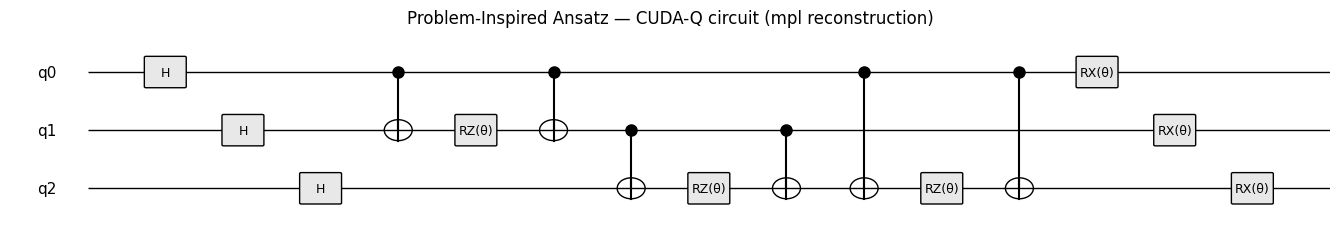

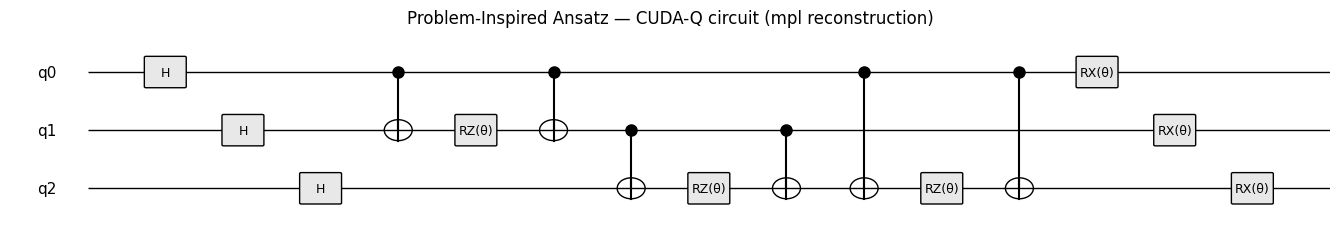

In [ ]:
# CUDA-Q has no native matplotlib circuit renderer, so we hand-build a diagram that
# mirrors Qiskit's drawing style (horizontal wires, boxed gate labels, same
# top-to-bottom qubit order) so the two circuit images are visually comparable.

gate_sequence = [("H", [0]), ("H", [1]), ("H", [2])]
for (i, j) in EDGES:
    gate_sequence += [("CX", [i, j]), ("RZ", [j]), ("CX", [i, j])]
gate_sequence += [("RX", [0]), ("RX", [1]), ("RX", [2])]

n_wires = N_QUBITS
n_steps = len(gate_sequence)
fig, ax = plt.subplots(figsize=(max(10, n_steps * 0.9), 2.5))

wire_y = {q: n_wires - 1 - q for q in range(n_wires)}  # q0 drawn on top, like Qiskit
for q in range(n_wires):
    ax.hlines(wire_y[q], 0, n_steps + 1, color="black", linewidth=1, zorder=1)
    ax.text(-0.4, wire_y[q], f"q{q}", ha="right", va="center", fontsize=11)

x = 1
for gate, qs in gate_sequence:
    if gate == "CX":
        control, target = qs
        ax.plot([x, x], [wire_y[control], wire_y[target]], color="black", zorder=2)
        ax.plot(x, wire_y[control], "o", color="black", markersize=8, zorder=3)
        circ = plt.Circle((x, wire_y[target]), 0.18, fill=False, color="black", zorder=3)
        ax.add_patch(circ)
        ax.plot([x, x], [wire_y[target] - 0.18, wire_y[target] + 0.18], color="black", zorder=3)
    else:
        q = qs[0]
        box = patches.FancyBboxPatch((x - 0.25, wire_y[q] - 0.25), 0.5, 0.5,
                                      boxstyle="round,pad=0.02", edgecolor="black",
                                      facecolor="#e8e8e8", zorder=3)
        ax.add_patch(box)
        label = gate if gate not in ("RZ", "RX") else f"{gate}(θ)"
        ax.text(x, wire_y[q], label, ha="center", va="center", fontsize=9, zorder=4)
    x += 1

ax.set_xlim(-1, n_steps + 1)
ax.set_ylim(-0.7, n_wires - 0.3)
ax.axis("off")
ax.set_title("Problem-Inspired Ansatz — CUDA-Q circuit (mpl reconstruction)")
fig.tight_layout()
fig.savefig("qaoa_problem_inspired_cudaq_circuit.png", dpi=150, bbox_inches="tight")
fig

In [ ]:
# CUDA-Q (current SDK) has no dense-operator-extraction API analogous to
# qiskit.quantum_info.Operator, so per the matrix-cross-check rule we build the
# operator by hand only here (method a) and cross-check it via the STATEVECTOR
# comparison in the next cells instead of a matrix diff.

I2 = np.eye(2, dtype=complex)
H2 = (1 / np.sqrt(2)) * np.array([[1, 1], [1, -1]], dtype=complex)


def single_qubit_op(op2x2, target, n=N_QUBITS):
    mats = [op2x2 if q == target else I2 for q in range(n - 1, -1, -1)]
    out = mats[0]
    for m in mats[1:]:
        out = np.kron(out, m)
    return out


def cx_matrix(control, target, n=N_QUBITS):
    dim = 2 ** n
    U = np.zeros((dim, dim), dtype=complex)
    for basis in range(dim):
        bits = [(basis >> k) & 1 for k in range(n)]
        if bits[control] == 1:
            bits[target] ^= 1
        newbasis = sum(b << k for k, b in enumerate(bits))
        U[newbasis, basis] = 1
    return U


def rz_matrix(theta, target, n=N_QUBITS):
    m = np.array([[np.exp(-1j * theta / 2), 0], [0, np.exp(1j * theta / 2)]], dtype=complex)
    return single_qubit_op(m, target, n)


def rx_matrix(theta, target, n=N_QUBITS):
    m = np.array([[np.cos(theta / 2), -1j * np.sin(theta / 2)],
                  [-1j * np.sin(theta / 2), np.cos(theta / 2)]], dtype=complex)
    return single_qubit_op(m, target, n)


dim = 2 ** N_QUBITS
H_all = single_qubit_op(H2, 0)
for q in range(1, N_QUBITS):
    H_all = single_qubit_op(H2, q) @ H_all

U_cost_hand = np.eye(dim, dtype=complex)
for (i, j) in EDGES:
    U_edge = cx_matrix(i, j) @ rz_matrix(2 * GAMMA, j) @ cx_matrix(i, j)
    U_cost_hand = U_edge @ U_cost_hand

U_mix_hand = np.eye(dim, dtype=complex)
for q in range(N_QUBITS):
    U_mix_hand = rx_matrix(2 * BETA, q) @ U_mix_hand

U_full_hand = U_mix_hand @ U_cost_hand @ H_all
print("Hand-built full ansatz unitary (rounded, basis |000>..|111>, qubit0=rightmost):")
print(np.round(U_full_hand, 4))

Hand-built full ansatz unitary (rounded, basis |000>..|111>, qubit0=rightmost):
[[-0.0396-0.5576j -0.0957-0.231j  -0.0957-0.231j  -0.231 -0.0957j
  -0.0957-0.231j  -0.231 -0.0957j -0.231 -0.0957j -0.5576-0.0396j]
 [ 0.231 +0.0957j -0.5576-0.0396j  0.0957+0.231j  -0.231 -0.0957j
   0.0957+0.231j  -0.231 -0.0957j  0.0396+0.5576j -0.0957-0.231j ]
 [ 0.231 +0.0957j  0.0957+0.231j  -0.5576-0.0396j -0.231 -0.0957j
   0.0957+0.231j   0.0396+0.5576j -0.231 -0.0957j -0.0957-0.231j ]
 [ 0.231 +0.0957j -0.0957-0.231j  -0.0957-0.231j   0.0396+0.5576j
   0.5576+0.0396j -0.231 -0.0957j -0.231 -0.0957j  0.0957+0.231j ]
 [ 0.231 +0.0957j  0.0957+0.231j   0.0957+0.231j   0.0396+0.5576j
  -0.5576-0.0396j -0.231 -0.0957j -0.231 -0.0957j -0.0957-0.231j ]
 [ 0.231 +0.0957j -0.0957-0.231j   0.5576+0.0396j -0.231 -0.0957j
  -0.0957-0.231j   0.0396+0.5576j -0.231 -0.0957j  0.0957+0.231j ]
 [ 0.231 +0.0957j  0.5576+0.0396j -0.0957-0.231j  -0.231 -0.0957j
  -0.0957-0.231j  -0.231 -0.0957j  0.0396+0.5576j  0.095

In [ ]:
state = cudaq.get_state(problem_inspired_ansatz, GAMMA, BETA)
amps_cudaq = np.array(state, dtype=complex)  # native CUDA-Q order: qubit0 = MSB

amps_ours = np.zeros(dim, dtype=complex)
for i_cudaq in range(dim):
    bstr_cudaq = format(i_cudaq, f"0{N_QUBITS}b")   # left-to-right = q0, q1, ..., q(n-1)
    bstr_ours = reverse_bitstring(bstr_cudaq)         # left-to-right = q(n-1), ..., q1, q0
    i_ours = int(bstr_ours, 2)
    amps_ours[i_ours] = amps_cudaq[i_cudaq]

# Global phase normalization: identical rule to the Qiskit notebook
idx0 = next(k for k in range(dim) if abs(amps_ours[k]) > 1e-9)
phase = np.angle(amps_ours[idx0])
amps_norm = amps_ours * np.exp(-1j * phase)

probs = {}
print("CUDA-Q statevector, remapped to qubit0=rightmost convention, phase-normalized:")
for i in range(dim):
    bstr = format(i, f"0{N_QUBITS}b")
    p = abs(amps_norm[i]) ** 2
    probs[bstr] = p
    print(f"|{bstr}>  amp = {amps_norm[i]:.4f}   prob = {p:.6f}")

probs_sorted = dict(sorted(probs.items()))
print("\nProbability dictionary (sorted by bitstring):")
print(probs_sorted)

CUDA-Q statevector, remapped to qubit0=rightmost convention, phase-normalized:
|000>  amp = 0.5590+0.0000j   prob = 0.312500
|001>  amp = -0.1118+0.2236j   prob = 0.062500
|010>  amp = -0.1118+0.2236j   prob = 0.062500
|011>  amp = -0.1118+0.2236j   prob = 0.062500
|100>  amp = -0.1118+0.2236j   prob = 0.062500
|101>  amp = -0.1118+0.2236j   prob = 0.062500
|110>  amp = -0.1118+0.2236j   prob = 0.062500
|111>  amp = 0.5590+0.0000j   prob = 0.312500

Probability dictionary (sorted by bitstring):
{'000': np.float64(0.3124999999999998), '001': np.float64(0.06249999999999996), '010': np.float64(0.062499999999999944), '011': np.float64(0.062499999999999944), '100': np.float64(0.062499999999999944), '101': np.float64(0.062499999999999944), '110': np.float64(0.06249999999999996), '111': np.float64(0.3124999999999998)}


**Ordering-fix note:** CUDA-Q's `get_state()` indexes qubit 0 as the leftmost/MSB bit,
the opposite of this project's qubit0=rightmost convention. Every amplitude index above
was remapped with `reverse_bitstring()` (defined earlier, in its own cell) before the
global-phase normalization was applied — the same normalization rule used in the Qiskit
notebook. The `cudaq.sample()` counts below get the identical treatment.

In [ ]:
result = cudaq.sample(problem_inspired_ansatz, GAMMA, BETA, shots_count=SHOTS)

counts_cudaq = {bstr: result.count(bstr) for bstr in result}
counts_ours = {}
for bstr_cudaq, c in counts_cudaq.items():
    bstr_ours = reverse_bitstring(bstr_cudaq)
    counts_ours[bstr_ours] = counts_ours.get(bstr_ours, 0) + c

counts_ours_sorted = dict(sorted(counts_ours.items()))
sample_probs = {k: v / SHOTS for k, v in counts_ours_sorted.items()}

print("Raw CUDA-Q counts (native qubit0=leftmost convention):", dict(counts_cudaq))
print("\nRemapped counts (qubit0=rightmost, matches Qiskit):", counts_ours_sorted)
print("\nSampled probabilities:", sample_probs)

Raw CUDA-Q counts (native qubit0=leftmost convention): {'110': 639, '101': 630, '100': 590, '011': 632, '001': 653, '111': 3138, '010': 626, '000': 3092}

Remapped counts (qubit0=rightmost, matches Qiskit): {'000': 3092, '001': 590, '010': 626, '011': 639, '100': 653, '101': 630, '110': 632, '111': 3138}

Sampled probabilities: {'000': 0.3092, '001': 0.059, '010': 0.0626, '011': 0.0639, '100': 0.0653, '101': 0.063, '110': 0.0632, '111': 0.3138}


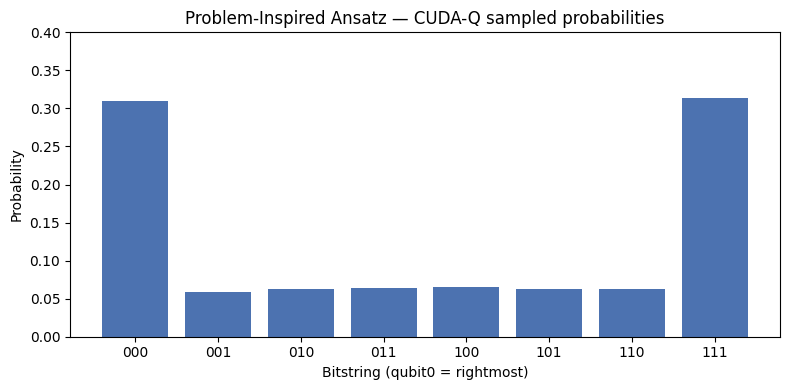

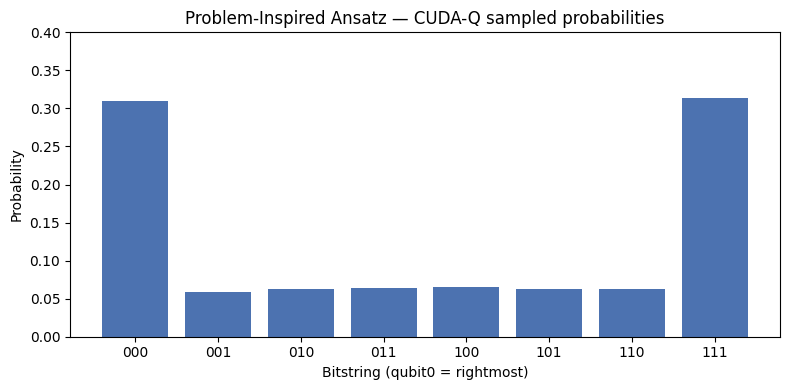

In [ ]:
fig2, ax = plt.subplots(figsize=(8, 4))
bitstrings = list(counts_ours_sorted.keys())
values = [v / SHOTS for v in counts_ours_sorted.values()]
ax.bar(bitstrings, values, color="#4C72B0")
ax.set_ylim(0, 0.4)
ax.set_xlabel("Bitstring (qubit0 = rightmost)")
ax.set_ylabel("Probability")
ax.set_title("Problem-Inspired Ansatz — CUDA-Q sampled probabilities")
fig2.tight_layout()
fig2.savefig("qaoa_problem_inspired_cudaq_histogram.png", dpi=150, bbox_inches="tight")
fig2

In [ ]:
# CUDA-Q kernels don't expose a circuit.depth()/count_ops() API like Qiskit's
# QuantumCircuit, so resource counts are derived from the same gate_sequence list
# used for the mpl drawing above (kept in exact sync with the kernel body).
gate_counts = {}
for gate, _ in gate_sequence:
    gate_counts[gate] = gate_counts.get(gate, 0) + 1

print("Gate counts:", gate_counts)
print("Total gate count:", len(gate_sequence))
print("Number of qubits:", N_QUBITS)

Gate counts: {'H': 3, 'CX': 6, 'RZ': 3, 'RX': 3}
Total gate count: 15
Number of qubits: 3


**Convention notes (recap):**
- Bit order: every `get_state()` index and every `sample()` bitstring was reversed via
  `reverse_bitstring()` to convert CUDA-Q's native qubit0=leftmost convention into this
  project's shared qubit0=rightmost convention (matching Qiskit).
- Global phase: after remapping, the statevector was multiplied by `exp(-i*phase)`
  where `phase` is the angle of the first amplitude (ascending bitstring order) with
  magnitude `> 1e-9`, so that amplitude becomes real and positive.
- Basis ordering used everywhere (post-remap): ascending binary, `{|000>, ..., |111>}`.

In [ ]:
CUDAQ_RESULT = probs_sorted
print("CUDAQ_RESULT =", CUDAQ_RESULT)

CUDAQ_RESULT = {'000': np.float64(0.3124999999999998), '001': np.float64(0.06249999999999996), '010': np.float64(0.062499999999999944), '011': np.float64(0.062499999999999944), '100': np.float64(0.062499999999999944), '101': np.float64(0.062499999999999944), '110': np.float64(0.06249999999999996), '111': np.float64(0.3124999999999998)}
